# Fourier Space Single Image Resolution Estimation

Demonstration of FRC resolution estimation of a single image & dataset of images

In [1]:
#change directory first to import dependencies from MIPLIB source code

import os
os.chdir('D:\\BOX\\Box Sync\\RA\\codes\\Imaging\\FRC\\miplib-public\\')
cwd = os.getcwd()
cwd
os.add_dll_directory(r"C:\Users\yx2011\AppData\Local\anaconda3")

<AddedDllDirectory('C:\\Users\\yx2011\\AppData\\Local\\anaconda3')>

In [2]:
%matplotlib inline

import numpy as np
import imageio
import matplotlib.pyplot as plt
import pandas as pd
import miplib.ui.plots.image as showim
import miplib.data.io.read as imread
import miplib.processing.image as imops
from miplib.data.containers.image import Image

# import miplib.analysis.resolution.fourier_ring_correlation as frc
from miplib.data.containers.fourier_correlation_data import FourierCorrelationData,\
FourierCorrelationDataCollection
from miplib.analysis.resolution import analysis as fsc_analysis, fourier_ring_correlation
from miplib.processing import windowing
import miplib.data.iterators.fourier_ring_iterators as iterators

import miplib.ui.plots.frc as frcplots
# from miplib.processing.fft_filters import fft_filter, butterworth_fft_filter, gaussian_fft_filter
from miplib.ui.cli import miplib_entry_point_options as options

import urllib.request as dl

from miplib.data.core.dictionary import FixedDictionary

C:\Users\yx2011\AppData\Local\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been deprecated
  "class": algorithms.Blowfish,


In [3]:
class FRC(object):
    """
    A class for calcuating 2D Fourier ring correlation. Contains
    methods to calculate the FRC as well as to plot the results.
    """

    def __init__(self, image1, image2, iterator):
        assert isinstance(image1, Image)
        assert isinstance(image2, Image)

        if image1.shape != image2.shape or tuple(image1.spacing) != tuple(image2.spacing):
            raise ValueError("The image dimensions do not match")
        if image1.ndim != 2:
            raise ValueError("Fourier ring correlation requires 2D images.")

        self.pixel_size = image1.spacing[0]

        # Expand to square
        image1 = imops.zero_pad_to_cube(image1)
        image2 = imops.zero_pad_to_cube(image2)

        self.iterator = iterator
        # Calculate power spectra for the input images.
        self.fft_image1 = np.fft.fftshift(np.fft.fft2(image1))
        self.fft_image2 = np.fft.fftshift(np.fft.fft2(image2))

        # Get the Nyquist frequency
        self.freq_nyq = int(np.floor(image1.shape[0] / 2.0))

    def execute(self):
        """
        Calculate the FRC
        :return: Returns the FRC results.

        """
        radii = self.iterator.radii
        c1 = np.zeros(radii.shape, dtype=np.float32)
        c2 = np.zeros(radii.shape, dtype=np.float32)
        c3 = np.zeros(radii.shape, dtype=np.float32)
        points = np.zeros(radii.shape, dtype=np.float32)

        for ind_ring, idx in self.iterator:
            subset1 = self.fft_image1[ind_ring]
            subset2 = self.fft_image2[ind_ring]
            c1[idx] = np.sum(subset1 * np.conjugate(subset2)).real
            c2[idx] = np.sum(np.abs(subset1) ** 2)
            c3[idx] = np.sum(np.abs(subset2) ** 2)

            points[idx] = len(subset1)

        # Calculate FRC
        spatial_freq = radii.astype(np.float32) / self.freq_nyq
        n_points = np.array(points)

        with np.errstate(divide="ignore", invalid="ignore"):
            frc = np.abs(c1) / np.sqrt(c2 * c3)
            frc[frc == np.inf] = 0.0
            frc = np.nan_to_num(frc)


        data_set = FourierCorrelationData()
        data_set.correlation["correlation"] = frc
        data_set.correlation["frequency"] = spatial_freq
        data_set.correlation["points-x-bin"] = n_points

        return data_set

## Setup

I expose some options for the FRC here. None of them you typically have to touch, but naturally can, e.g. to adjust the binning or the threshold.

the most important parameter is threshold, which is typically left to be the information theoretic 'half-bit' criterion, i.e., amount of information needed to encode half a bit from the image.

In [8]:
# args_list = ("None --bin-delta=1  --frc-curve-fit-type=smooth-spline "  
#              " --resolution-threshold-criterion=fixed").split()

args_list = ("None --bin-delta=1  --frc-curve-fit-type=smooth-spline "
            " --resolution-threshold-criterion=half-bit").split()
            
args = options.get_frc_script_options(args_list)

print (args)


Namespace(directory='None', debug=False, frc_mode='one-image', pathout=None, verbose=False, working_directory='/home/sami/Data', show_plots=False, show_image=False, scale=100, channel=0, jupyter=False, test_drive=False, evaluate_results=False, temp_dir=None, carma_gate_idx=0, carma_det_idx=0, plot_size=(2.5, 2.5), save_plots=False, enhance_contrast_on_save=False, d_bin=1, resol_square=False, frc_curve_fit_degree=8, resolution_threshold_curve_fit_degree=3, resolution_threshold_criterion='half-bit', resolution_threshold_value=0.14285714285714285, resolution_point_sigma=0.01, resolution_snr_value=0.25, d_angle=20, d_extract_angle=5.0, hollow_iterator=False, min_filter=False, disable_hamming=False, frc_curve_fit_type='smooth-spline')


## Calculate resolution

Here I estimate the resolution of the image with the single-image FRC method. 

## calculation on a single image

C:\Users\yx2011\AppData\Local\Temp\ipykernel_29224\2911025954.py:3: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread('192.9906.tif')


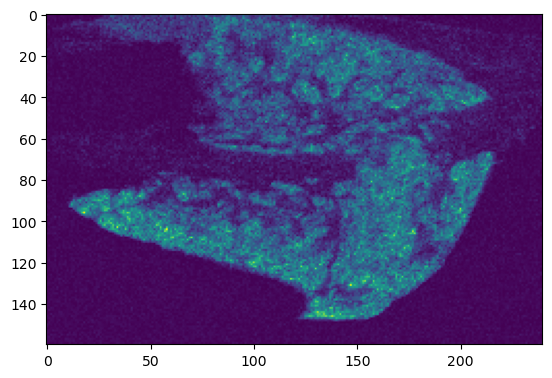

In [136]:
# image = imread.get_image('brain6peak755.png')
os.chdir('E:/IMAGING/LD_REIMS/HR_PFL/2024_08_06_TKT_13C_DCC3_A7_L6_5um_10Hz.raw/output_images')
image = imageio.imread('192.9906.tif')
image = image [:,:,1]
# image = image[:,100:200]
pixel = 5.0
image = Image(image,[pixel,pixel])
# image.shape

plt.imshow(image)
plt.show()

In [137]:
average = True
z_correction=0

frc_data = FourierCorrelationDataCollection()
if not args.disable_hamming:
    spacing = image.spacing
    image_w = Image(windowing.apply_hamming_window(image), spacing)
    image = imops.zero_pad_to_cube(image)
    # Split and make sure that the images are the same size
#     image1, image2 = imops.checkerboard_split(image_w)
#     image1, image2 = imops.reverse_checkerboard_split(image_w)
    image1, image2 = imops.summed_checkerboard_split(image)
    image1, image2 = imops.zero_pad_to_matching_shape(image1, image2)

    # Run FRC
    iterator = iterators.FourierRingIterator(image1.shape, args.d_bin)
    frc_task = FRC(image1, image2, iterator)
    frc_data[0] = frc_task.execute()

    if average:
        # Split and make sure that the images are the same size
#         image1, image2 = imops.reverse_checkerboard_split(image)
        image1, image2 = imops.summed_checkerboard_split(image)
        image1, image2 = imops.zero_pad_to_matching_shape(image1, image2)
        iterator = iterators.FourierRingIterator(image1.shape, args.d_bin)
        frc_task = FRC(image1, image2, iterator)

        frc_data[0].correlation["correlation"] *= 0.5
        frc_data[0].correlation["correlation"] += 0.5*frc_task.execute().correlation["correlation"]

    freqs = frc_data[0].correlation["frequency"].copy()

    analyzer = fsc_analysis.FourierCorrelationAnalysis(frc_data, image.spacing[0], args)

    result = analyzer.execute(z_correction=z_correction)[0]
    resolution = result.resolution['resolution']
    print('the resolution of this image is '+str(resolution)+' um')

the resolution of this image is 13.200637827220456 um


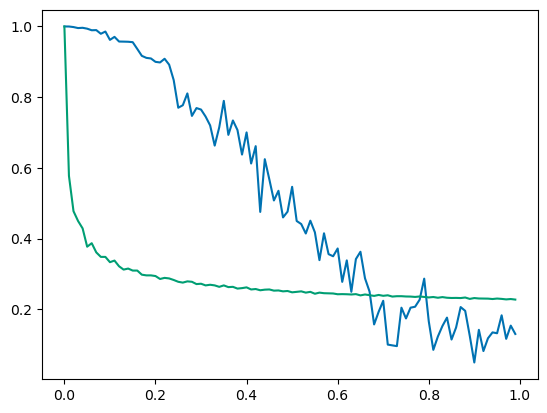

In [17]:
plt.plot(result.correlation["frequency"],result.correlation["correlation"])
plt.plot(result.correlation["frequency"],result.resolution['threshold'])
plt.show()

In [22]:
# check cut-off
float(result.resolution['resolution-point'][1])

0.6849608421325684

## calculation for entire dataset

In [127]:
average = True
z_correction=0

frc_data = FourierCorrelationDataCollection()
resolutions = []
mz = []
errors = []
pixel = 5.0 #in um
directory = 'E:/IMAGING/LD_REIMS/HR_PFL/2024_08_06_TKT_13C_DCC3_A7_L6_5um_10Hz.raw/output_images2'

for file in os.listdir(directory):
#     if file.endswith(".png"):
    if file.endswith(".tif"):
        try:
            mz.append(float(file[:-4]))
            image = imageio.imread(file)
            image = image[:,:,1]
#             image = image[:,100:200]
            image = Image(image,[pixel,pixel])
            # Hamming Windowing
            if not args.disable_hamming:
                spacing = image.spacing
                image = Image(windowing.apply_hamming_window(image), spacing)
            
            image = imops.zero_pad_to_cube(image)
            # Split and make sure that the images are the same siz
            image1, image2 = imops.summed_checkerboard_split(image)
#             image1, image2 = imops.checkerboard_split(image)
            #image1, image2 = imops.reverse_checkerboard_split(image)
            image1, image2 = imops.zero_pad_to_matching_shape(image1, image2)

            # Run FRC
            iterator = iterators.FourierRingIterator(image1.shape, args.d_bin)
            frc_task = FRC(image1, image2, iterator)
            frc_data[0] = frc_task.execute()

            if average:
                # Split and make sure that the images are the same size
                image1, image2 = imops.summed_checkerboard_split(image)
#                 image1, image2 = imops.reverse_checkerboard_split(image)
                image1, image2 = imops.zero_pad_to_matching_shape(image1, image2)
                iterator = iterators.FourierRingIterator(image1.shape, args.d_bin)
                frc_task = FRC(image1, image2, iterator)

                frc_data[0].correlation["correlation"] *= 0.5
                frc_data[0].correlation["correlation"] += 0.5*frc_task.execute().correlation["correlation"]

            freqs = frc_data[0].correlation["frequency"].copy()

            analyzer = fsc_analysis.FourierCorrelationAnalysis(frc_data, image.spacing[0], args)

            result = analyzer.execute(z_correction=z_correction)[0]
            if result.resolution['resolution'] != None:
                resolutions.append(result.resolution['resolution'])
            else:
                errors.append(float(file[:-4]))
        except:
             errors.append(float(file[:-4]))
             print("Could not correlate image "+file) 

C:\Users\yx2011\AppData\Local\Temp\ipykernel_29224\2945558283.py:16: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread(file)


Could not correlate image 192.9906.tif


In [135]:
np.mean(filtered_res1)

29.8803499203017

the average & median resolution is 46.50576752290301 & 46.672741899262924 um respectively.


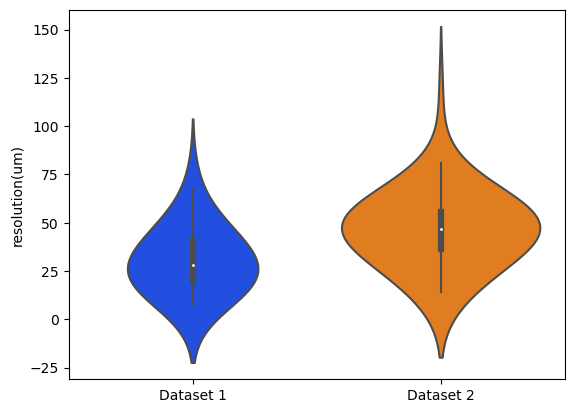

In [134]:
import seaborn as sns

filtered_res = resolutions.copy()
mz_fil = mz.copy()
mz_fil = [e for e in mz_fil if e not in errors]
# plt.boxplot(filtered_res)
inds = np.argsort(filtered_res)
mz_fil = [mz_fil[i] for i in inds]
filtered_res.sort()
ax = sns.violinplot(data=[filtered_res1,filtered_res],whis=5, palette = 'bright', scale = 'count', bw=1 )
ax.set_xticklabels(['Dataset 1','Dataset 2'])
ax.set_ylabel('resolution(um)')
# plt.ylim(0, 5)
output = pd.DataFrame(index=range(0,len(filtered_res)),columns=['m/z','Resolutions'])
output['m/z']=mz_fil
output['Resolutions']=filtered_res
print('the average & median resolution is '+str(np.mean(filtered_res))+' & '+str(np.median(filtered_res))+' um respectively.')

In [131]:
output.to_csv (r'FRC_resolutions.csv', index = False, header=True)
output

,m/z,Resolutions
0,417.1726,14.097501
1,190.1867,15.526443
2,128.0355,17.241665
3,122.9965,17.658824
4,223.1025,18.512941
...,...,...
74,255.2327,70.316786
75,51.2191,75.084304
76,420.1860,78.171927
77,129.0387,80.808090


## calculation using 2 images

In [255]:
z_correction=0

image1 = imageio.imread('brain6peak755.png')
image2 = imageio.imread('brain6peak555.png')

image1 = image1[:,:,1]
# image1 = (image1 - np.min(image1)) / (np.max(image1) - np.min(image1))
image2 = image2[:,:,1]
# image2 = (image2 - np.min(image2)) / (np.max(image2) - np.min(image2))

# image = image[:,100:200]
image1 = Image(image1,[100.0,100.0])
image2 = Image(image2,[100.0,100.0])
# image.shape

assert isinstance(image1, Image)
assert isinstance(image2, Image)

assert image1.shape == image2.shape

frc_data = FourierCorrelationDataCollection()

spacing = image1.spacing

if not args.disable_hamming:

    image1 = Image(windowing.apply_hamming_window(image1), spacing)
    image2 = Image(windowing.apply_hamming_window(image2), spacing)

# Run FRC
iterator = iterators.FourierRingIterator(image1.shape, args.d_bin)
frc_task = FRC(image1, image2, iterator)
frc_data[0] = frc_task.execute()

# Analyze results
analyzer = fsc_analysis.FourierCorrelationAnalysis(frc_data, image1.spacing[0], args)

result = analyzer.execute(z_correction=z_correction)[0]
print(result.resolution['resolution'])
print(2 * image.spacing[0] / result.resolution['resolution'])

14799.999641627082
0.013513513840734959


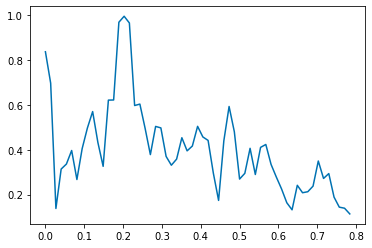

In [238]:
plt.plot(result.correlation["frequency"],result.correlation["correlation"])
plt.show()